# Projeto Integrador · Big Data · Mercado Imobiliário de São Paulo

<a href="https://colab.research.google.com/github/Real-Estate-VMs/real-estate/blob/main/notebooks/PI_BigData.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

**Empresa (fictícia):** JLeandro Imóveis · **Disciplina:** Big Data · **Módulo:** Data Science, 2º semestre de 2026

Este notebook segue as **6 etapas** do documento de orientações da disciplina:

| Etapa | Seção |
|---|---|
| 1. Definição do problema e da base | [1](#1) |
| 2. EDA | [2](#2) |
| 3. Armazenamento, ETL e OLAP | [3](#3) |
| 4. Data Mining e Machine Learning | [4](#4) |
| 5. Processamento distribuído (Spark / Hadoop) | [5](#5) |
| 6. Análise final e insights | [6](#6) |

**Como executar.** O notebook roda do início ao fim em dois modos, escolhidos automaticamente:

* **Modo `github`** (Google Colab ou qualquer máquina): lê os arquivos públicos do repositório no GitHub e monta o Data Warehouse **em memória** com DuckDB, usando as mesmas regras do ETL real.
* **Modo `dw`** (Colab conectado à VM `bigdata` por túnel SSH): lê o **Data Warehouse real** em PostgreSQL, alimentado automaticamente pelo pipeline.

As consultas SQL de OLAP são as mesmas nos dois modos.

In [1]:
import os
import sys

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    # O Colab já traz pandas, scikit-learn, matplotlib e seaborn
    get_ipython().run_line_magic("pip", "install -q duckdb==1.1.3 pyspark==3.5.3")
print("Rodando no Google Colab" if EM_COLAB else "Rodando fora do Colab (ex.: VM bigdata)")

Rodando fora do Colab (ex.: VM bigdata)


In [2]:
import ast
import json
import tempfile
import urllib.request
import warnings
from concurrent.futures import ThreadPoolExecutor
from decimal import Decimal

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

REPO = "Real-Estate-VMs/real-estate"
RAW_BASE = f"https://raw.githubusercontent.com/{REPO}/main"
PASTA_DADOS = os.path.join(tempfile.gettempdir(), "pi_bigdata")
# Na VM bigdata, REPO_LOCAL aponta para o clone que o ETL mantém atualizado: nada é baixado.
REPO_LOCAL = os.getenv("REPO_LOCAL") if os.path.isdir(os.getenv("REPO_LOCAL", "")) else None
os.makedirs(os.path.join(PASTA_DADOS, "raw"), exist_ok=True)
os.makedirs(os.path.join(PASTA_DADOS, "processed"), exist_ok=True)


def dw_disponivel():
    """True quando o notebook roda na VM bigdata com acesso ao PostgreSQL."""
    dsn = os.getenv("DW_DSN")
    if not dsn:
        return False
    try:
        import psycopg
        with psycopg.connect(dsn, connect_timeout=3):
            return True
    except Exception:
        return False


MODO = os.getenv("MODO_NOTEBOOK") or ("dw" if dw_disponivel() else "github")
print(f"Modo de execução: {MODO}")

Modo de execução: dw


In [3]:
def _arvore_repo():
    """Lista todos os arquivos do repositório numa única chamada à API do GitHub.

    Diferente de listar uma pasta (limite de 1000 itens), a árvore completa não corta os lotes antigos.
    """
    req = urllib.request.Request(
        f"https://api.github.com/repos/{REPO}/git/trees/main?recursive=1",
        headers={"Accept": "application/vnd.github+json", "User-Agent": "pi-bigdata-notebook"},
    )
    with urllib.request.urlopen(req, timeout=60) as resp:
        resposta = json.load(resp)
    if resposta.get("truncated"):
        print("[AVISO] a árvore do repositório veio truncada; alguns arquivos podem faltar")
    return [i["path"] for i in resposta["tree"] if i["type"] == "blob"]


ARVORE = None if REPO_LOCAL else _arvore_repo()


def listar_arquivos(pasta, extensao):
    """Lista os arquivos de uma pasta do repositório (clone local na VM, árvore do GitHub no Colab)."""
    if REPO_LOCAL:
        return sorted(f for f in os.listdir(os.path.join(REPO_LOCAL, pasta)) if f.endswith(extensao))
    return sorted(p.rsplit("/", 1)[1] for p in ARVORE if p.startswith(pasta + "/") and p.endswith(extensao))


def baixar(pasta, nome):
    """Devolve o caminho local de um arquivo do repositório, baixando-o uma vez se necessário."""
    if REPO_LOCAL:
        return os.path.join(REPO_LOCAL, pasta, nome)
    destino = os.path.join(PASTA_DADOS, pasta.split("/")[-1], nome)
    if not os.path.exists(destino):
        temporario = destino + ".part"  # evita deixar um arquivo pela metade se o download falhar
        urllib.request.urlretrieve(f"{RAW_BASE}/{pasta}/{nome}", temporario)
        os.replace(temporario, destino)
    return destino


def baixar_todos(pasta, nomes):
    """Baixa vários arquivos em paralelo (o gargalo é a latência, não a banda)."""
    with ThreadPoolExecutor(max_workers=16) as pool:
        return list(pool.map(lambda n: baixar(pasta, n), nomes))


arquivos_raw = listar_arquivos("data/raw", ".csv")
arquivos_processed = listar_arquivos("data/processed", ".parquet")
baixar_todos("data/raw", arquivos_raw)
baixar_todos("data/processed", arquivos_processed)
print(f"{len(arquivos_raw)} CSVs brutos e {len(arquivos_processed)} parquets tratados no repositório"
      + (" (lidos do clone local)" if REPO_LOCAL else " (baixados do GitHub)"))

11 CSVs brutos e 11 parquets tratados no repositório (lidos do clone local)


<a id="1"></a>
## 1. Definição do problema e da base

### Pergunta de análise
> **Quais fatores determinam o preço de um imóvel em São Paulo e quanto vale um imóvel antes de ser anunciado?**

Para a JLeandro Imóveis, responder isso significa precificar melhor, identificar imóveis anunciados abaixo do valor de mercado e saber onde concentrar a captação.

### Origem da base
A base é **sintética** e gerada pela própria solução (`scripts/generator.py`), para respeitar a LGPD: nenhum dado é de pessoa real. O generator roda na VM `generator`, cria entre 50 e 200 imóveis a cada 30 minutos e publica um CSV no GitHub. Para dar volume às análises, foi feita também uma **carga histórica** única de 20 mil registros (`--historico 20000 --seed 2026`).

O generator **injeta sujeira de propósito** (cerca de 10% dos registros): preço e área negativos ou zerados, quartos impossíveis (-1, 99) e o estado escrito de 6 formas diferentes. Isso permite praticar a limpeza.

In [4]:
partes = []
for nome in arquivos_raw:
    df = pd.read_csv(baixar("data/raw", nome), keep_default_na=True, na_values=[""])
    df["arquivo"] = nome
    partes.append(df)
bruto = pd.concat(partes, ignore_index=True)

print(f"Registros brutos : {len(bruto):,}")
print(f"Arquivos (lotes) : {bruto['arquivo'].nunique()}")
print(f"Período de vendas: {pd.to_datetime(bruto['sale_date']).min():%d/%m/%Y} a {pd.to_datetime(bruto['sale_date']).max():%d/%m/%Y}")
bruto.head()

Registros brutos : 21,393
Arquivos (lotes) : 11
Período de vendas: 01/01/2023 a 28/12/2026


,record_id,seller_id,seller_name,buyer_id,property_type,neighborhood,city,state,latitude,longitude,area_m2,bedrooms,bathrooms,parking_spots,year_built,furnished,condo_fee,price,sale_date,buyer_notes,arquivo
0,df42273b-b21d-4e00-bd56-6eccbf9c4966,S-007,Diego Alves,B-FDE70D23,commercial,Santana,São Paulo,Sao Paulo,-23.50,-46.62,103.20,0.00,1,1,1995,False,832.73,"982,375.53",2024-08-18,Asked about pet policy in the building.,listings_20260925_005450.csv
1,deca2836-5d96-4ea5-a09f-e202f334d5b1,S-005,Marcelo Ferreira,B-094B1EE4,house,Ipiranga,São Paulo,Sao Paulo,-23.60,-46.60,95.40,3.00,1,0,2009,False,0.00,"1,075,329.12",2024-03-08,"Interested in the view, wants to negotiate price.",listings_20260925_005450.csv
2,56c293a0-6b3c-43f5-8a85-dcd38f2805e4,S-016,Aline Gomes,B-3B35413E,penthouse,Itaim Bibi,São Paulo,S.Paulo,-23.59,-46.67,153.10,4.00,4,3,2007,True,"1,783.73","3,442,852.59",2024-03-16,"Interested in the view, wants to negotiate price.",listings_20260925_005450.csv
3,6d22f4ad-171f-48d6-9eec-9f10ba5586bc,S-004,Fernanda Costa,B-8C020AF0,house,Jabaquara,São Paulo,sp,-23.65,-46.64,254.90,5.00,1,1,2011,True,0.00,"2,711,772.53",2024-03-06,Needs parking for two cars.,listings_20260925_005450.csv
4,b890cf24-b57e-43d9-a700-13964ee1459a,S-016,Aline Gomes,B-9F285071,house,Cidade Dutra,São Paulo,SP,-23.70,-46.66,256.10,2.00,1,3,1989,False,0.00,"1,137,479.06",2026-05-25,Looking for a property near public transport.,listings_20260925_005450.csv


### Dicionário de dados

| Variável | Tipo | Descrição | Observações |
|---|---|---|---|
| `record_id` | texto (UUID) | Identificador único do imóvel | chave primária |
| `seller_id` / `seller_name` | texto | Corretor responsável | **nome não entra no DW (LGPD)** |
| `buyer_id` | texto | Comprador | vazio quando o imóvel não foi vendido |
| `property_type` | categórica | apartment, house, studio, commercial, penthouse | |
| `neighborhood` | categórica | Bairro (45 bairros de SP e região) | |
| `city` / `state` | categórica | Cidade e estado | `state` vem com 6 grafias diferentes |
| `latitude` / `longitude` | numérica contínua | Coordenadas do imóvel | |
| `area_m2` | numérica contínua | Área útil em m² | pode vir negativa, zero ou nula (sujeira) |
| `bedrooms` / `bathrooms` | numérica discreta | Quartos e banheiros | quartos podem vir -1, -2 ou 99 (sujeira) |
| `parking_spots` | numérica discreta | Vagas de garagem | |
| `year_built` | numérica discreta | Ano de construção | |
| `furnished` | booleana | Mobiliado | |
| `condo_fee` | numérica contínua | Condomínio (R$) | 0 para casas |
| `price` | numérica contínua | Preço (R$) — **variável alvo** | pode vir negativo, zero ou nulo (sujeira) |
| `sale_date` | data | Data da venda | vazia quando não vendido |
| `buyer_notes` | texto livre | Observação do comprador | dado **semiestruturado** |

### Relação com os 5 Vs do Big Data

In [5]:
lotes = bruto[bruto["arquivo"] != "listings_20261111_000000.csv"].groupby("arquivo").size()
sujos = (
    (bruto["price"].isna() | (bruto["price"] <= 0))
    | (bruto["area_m2"].isna() | (bruto["area_m2"] <= 0))
    | (bruto["bedrooms"].notna() & ((bruto["bedrooms"] < 0) | (bruto["bedrooms"] > 20)))
)
cinco_vs = pd.DataFrame({
    "V": ["Volume", "Velocidade", "Variedade", "Veracidade", "Valor"],
    "Evidência no projeto": [
        f"{len(bruto):,} registros em {bruto['arquivo'].nunique()} lotes; cresce sem parar",
        f"novo lote a cada 30 min (média de {lotes.mean():.0f} imóveis por lote) ≈ {lotes.mean() * 48:,.0f}/dia",
        "dados estruturados (CSV/parquet), texto livre (buyer_notes) e coordenadas geográficas",
        f"{sujos.mean():.1%} dos registros com valores inválidos; estado com {bruto['state'].nunique()} grafias",
        "preço justo por imóvel, oportunidades abaixo do mercado e regiões mais valorizadas",
    ],
})
cinco_vs

,V,Evidência no projeto
0,Volume,"21,393 registros em 11 lotes; cresce sem parar"
1,Velocidade,novo lote a cada 30 min (média de 139 imóveis ...
2,Variedade,"dados estruturados (CSV/parquet), texto livre ..."
3,Veracidade,9.1% dos registros com valores inválidos; esta...
4,Valor,"preço justo por imóvel, oportunidades abaixo d..."


**Limitações da base.** Por ser sintética, o preço segue uma regra do próprio generator (área × preço do m² sorteado dentro de uma faixa por tipo de região). Os padrões encontrados são, portanto, os que o gerador cria; métricas de modelo tendem a ser melhores do que seriam com dados reais. Isso é discutido na seção 6.

<a id="2"></a>
## 2. Análise Exploratória de Dados (EDA)

### 2.1 Tipos de variáveis

In [6]:
tipos = pd.DataFrame({
    "tipo pandas": bruto.dtypes.astype(str),
    "valores únicos": bruto.nunique(),
    "exemplo": bruto.iloc[0],
})
tipos

,tipo pandas,valores únicos,exemplo
record_id,object,21393,df42273b-b21d-4e00-bd56-6eccbf9c4966
seller_id,object,20,S-007
seller_name,object,20,Diego Alves
buyer_id,object,14856,B-FDE70D23
property_type,object,5,commercial
neighborhood,object,45,Santana
city,object,1,São Paulo
state,object,6,Sao Paulo
latitude,float64,20029,-23.50
longitude,float64,19925,-46.62


### 2.2 Valores ausentes, duplicidades e inconsistências

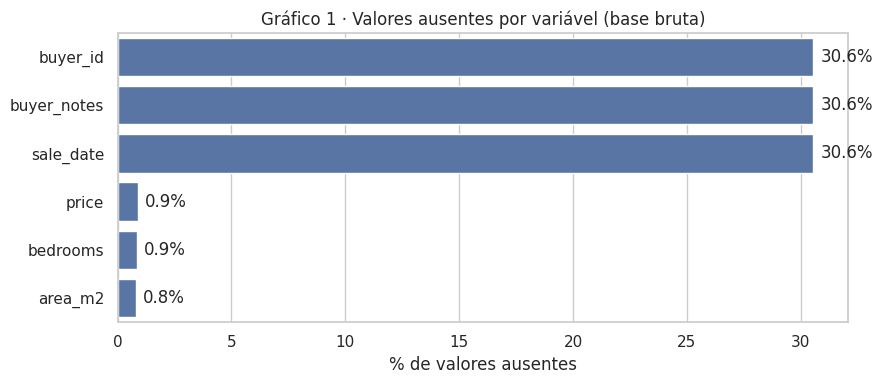

Registros duplicados (record_id): 0


In [7]:
ausentes = (bruto.isna().mean() * 100).sort_values(ascending=False)
ausentes = ausentes[ausentes > 0]

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=ausentes.values, y=ausentes.index, ax=ax, color="#4C72B0")
ax.set_xlabel("% de valores ausentes")
ax.set_ylabel("")
ax.set_title("Gráfico 1 · Valores ausentes por variável (base bruta)")
for i, v in enumerate(ausentes.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

print("Registros duplicados (record_id):", bruto["record_id"].duplicated().sum())

**Interpretação (Gráfico 1).** Três variáveis têm cerca de 30% de valores ausentes: `buyer_id`, `sale_date` e `buyer_notes`. São **ausências estruturais**: o imóvel ainda não foi vendido, então não há comprador, data nem observação. Isso não é erro e vira a variável `vendido`. Já `price`, `area_m2` e `bedrooms` têm em torno de 1% de nulos cada: essas, sim, são falhas de coleta (a sujeira injetada pelo generator). Não há registros duplicados.

In [8]:
inconsistencias = pd.Series({
    "price <= 0": (bruto["price"] <= 0).sum(),
    "price nulo": bruto["price"].isna().sum(),
    "area_m2 <= 0": (bruto["area_m2"] <= 0).sum(),
    "area_m2 nula": bruto["area_m2"].isna().sum(),
    "bedrooms fora de 0 a 20": (bruto["bedrooms"].notna() & ((bruto["bedrooms"] < 0) | (bruto["bedrooms"] > 20))).sum(),
    "sale_date no futuro": (pd.to_datetime(bruto["sale_date"]) > pd.Timestamp.today()).sum(),
}, name="registros")
inconsistencias = inconsistencias.to_frame()
inconsistencias["% da base"] = (inconsistencias["registros"] / len(bruto) * 100).round(1)
display(inconsistencias)
print("Grafias do campo state:")
bruto["state"].value_counts()

,registros,% da base
price <= 0,556,2.60
price nulo,192,0.90
area_m2 <= 0,515,2.40
area_m2 nula,175,0.80
bedrooms fora de 0 a 20,514,2.40
sale_date no futuro,482,2.30


Grafias do campo state:


state
São Paulo    3665
Sp           3652
SP           3575
sp           3534
Sao Paulo    3522
S.Paulo      3445
Name: count, dtype: int64

**Interpretação.** Cada tipo de problema atinge entre 1% e 3% da base: preço nulo ou não positivo, área nula ou não positiva e quartos impossíveis (-1, -2, 99). O campo `state` aparece com 6 grafias, todas com frequência parecida, para o mesmo estado: sem padronização, um agrupamento por estado mostraria 6 estados. Há também **vendas com data no futuro** (cerca de 3% das vendas), porque o generator sorteia datas até o fim de 2026. Essas vendas foram **mantidas**, já que preço e área são válidos, e o problema fica registrado como limitação da base.

### 2.3 Limpeza e transformações

As mesmas regras do script `scripts/processing.R` (que roda no pipeline do GitHub Actions) são aplicadas aqui em pandas, e o resultado é comparado com os parquets gerados pelo R:

1. `state` padronizado para `SP`;
2. `sale_date` convertido para data;
3. remove `price` nulo ou ≤ 0 e `area_m2` nula ou ≤ 0 (não há como corrigir: são a base do preço por m²);
4. remove `bedrooms` fora de 0 a 20, mantendo os nulos (o imóvel continua válido para análises de preço);
5. **variáveis derivadas:** `preco_m2`, `regiao` (Nobre, Intermediária, Periférica) e `vendido`.

A região vem do mapeamento de bairros do próprio generator, lido do código-fonte (sem executá-lo).

In [9]:
if REPO_LOCAL:
    fonte_generator = open(os.path.join(REPO_LOCAL, "scripts", "generator.py"), encoding="utf-8").read()
else:
    fonte_generator = urllib.request.urlopen(f"{RAW_BASE}/scripts/generator.py", timeout=30).read().decode()
for no in ast.parse(fonte_generator).body:
    if isinstance(no, ast.Assign) and isinstance(no.targets[0], ast.Name) and no.targets[0].id == "SP_NEIGHBORHOODS":
        BAIRROS = ast.literal_eval(no.value)
REGIAO_PT = {"noble": "Nobre", "mid": "Intermediária", "peripheral": "Periférica"}
REGIAO_DO_BAIRRO = {nome: REGIAO_PT[zona] for nome, _, _, zona in BAIRROS}

limpo = bruto.copy()
limpo["state"] = "SP"
limpo["sale_date"] = pd.to_datetime(limpo["sale_date"], errors="coerce")
limpo = limpo[limpo["price"].notna() & (limpo["price"] > 0)]
limpo = limpo[limpo["area_m2"].notna() & (limpo["area_m2"] > 0)]
limpo = limpo[limpo["bedrooms"].isna() | limpo["bedrooms"].between(0, 20)]
limpo["preco_m2"] = limpo["price"] / limpo["area_m2"]
limpo["regiao"] = limpo["neighborhood"].map(REGIAO_DO_BAIRRO)
limpo["vendido"] = limpo["sale_date"].notna()

linhas_parquet = sum(len(pd.read_parquet(baixar("data/processed", n))) for n in arquivos_processed)
print(f"Antes da limpeza : {len(bruto):,}")
print(f"Depois (pandas)  : {len(limpo):,}  ({1 - len(limpo) / len(bruto):.1%} removidos)")
print(f"Parquets do R    : {linhas_parquet:,}")

Antes da limpeza : 21,393
Depois (pandas)  : 19,441  (9.1% removidos)
Parquets do R    : 19,441


**Interpretação.** A limpeza em pandas chega **exatamente ao mesmo número de registros** que os parquets gerados pelo R no pipeline, o que confirma que as duas implementações aplicam as mesmas regras. Cerca de 9% dos registros são removidos, praticamente todos por preço ou área inválidos, o que bate com a taxa de cerca de 10% de sujeira configurada no generator.

### 2.4 Estatística descritiva

In [10]:
numericas = ["price", "area_m2", "preco_m2", "bedrooms", "bathrooms", "parking_spots", "condo_fee", "year_built"]
descritiva = limpo[numericas].describe().T
descritiva["cv"] = descritiva["std"] / descritiva["mean"]
descritiva

,count,mean,std,min,25%,50%,75%,max,cv
price,"19,441.00","1,825,635.43","1,598,389.51","62,026.96","625,029.14","1,344,219.68","2,526,897.19","9,769,648.58",0.88
area_m2,"19,441.00",164.62,102.03,20.00,67.40,155.80,245.40,399.80,0.62
preco_m2,"19,441.00","11,058.62","5,819.75","3,001.41","6,636.58","9,647.61","14,455.30","24,998.04",0.53
bedrooms,"19,255.00",1.99,1.88,0.00,0.00,2.00,4.00,5.00,0.94
bathrooms,"19,441.00",1.90,1.14,1.00,1.00,1.00,3.00,5.00,0.60
parking_spots,"19,441.00",1.50,1.12,0.00,0.00,2.00,2.00,3.00,0.75
condo_fee,"19,441.00","1,125.74",793.99,0.00,453.12,"1,128.54","1,813.25","2,499.99",0.71
year_built,"19,441.00","1,999.42",14.44,"1,975.00","1,987.00","1,999.00","2,012.00","2,024.00",0.01


In [11]:
categoricas = pd.DataFrame({
    "variável": ["property_type", "regiao", "neighborhood", "furnished", "vendido"],
    "moda": [limpo[c].mode()[0] for c in ["property_type", "regiao", "neighborhood", "furnished", "vendido"]],
    "categorias": [limpo[c].nunique() for c in ["property_type", "regiao", "neighborhood", "furnished", "vendido"]],
})
categoricas

,variável,moda,categorias
0,property_type,apartment,5
1,regiao,Intermediária,3
2,neighborhood,Aclimação,45
3,furnished,True,2
4,vendido,True,2


### 2.5 Visualizações

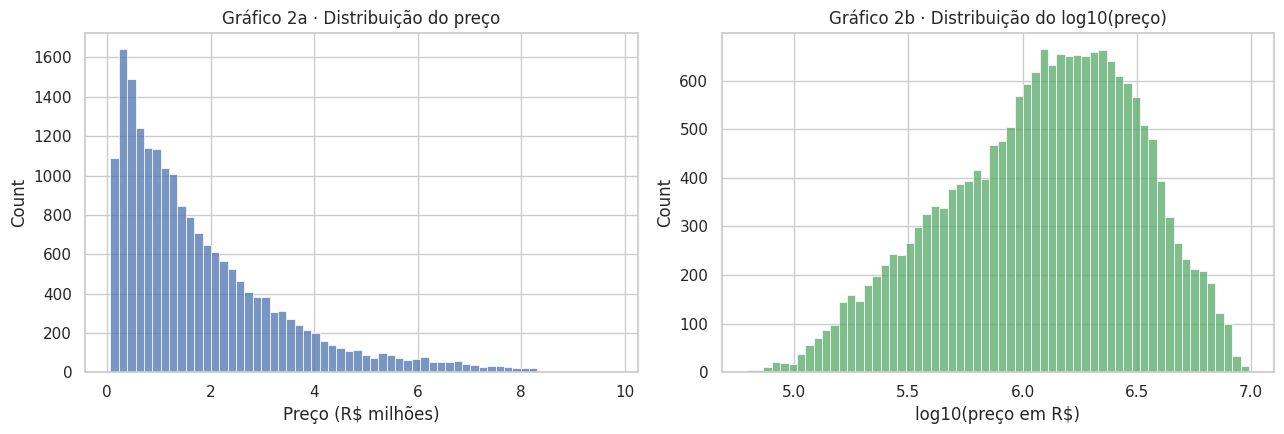

Assimetria do preço: 1.52 | mediana R$ 1,344,220 | média R$ 1,825,635


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(limpo["price"] / 1e6, bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Gráfico 2a · Distribuição do preço")
axes[0].set_xlabel("Preço (R$ milhões)")
sns.histplot(np.log10(limpo["price"]), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("Gráfico 2b · Distribuição do log10(preço)")
axes[1].set_xlabel("log10(preço em R$)")
plt.tight_layout()
plt.show()
print(f"Assimetria do preço: {limpo['price'].skew():.2f} | mediana R$ {limpo['price'].median():,.0f} | média R$ {limpo['price'].mean():,.0f}")

**Interpretação (Gráfico 2).** O preço tem **assimetria à direita** (coeficiente em torno de 1,5): a mediana fica perto de R$ 1,3 milhão e a média perto de R$ 1,8 milhão, puxada por poucos imóveis grandes em bairros nobres. Em escala logarítmica a distribuição fica mais simétrica, mas com vários "picos", reflexo da mistura de tipos de imóvel e de regiões com patamares de preço diferentes. Por isso a média sozinha engana: nas comparações usamos a mediana e, principalmente, o **preço por m²**.

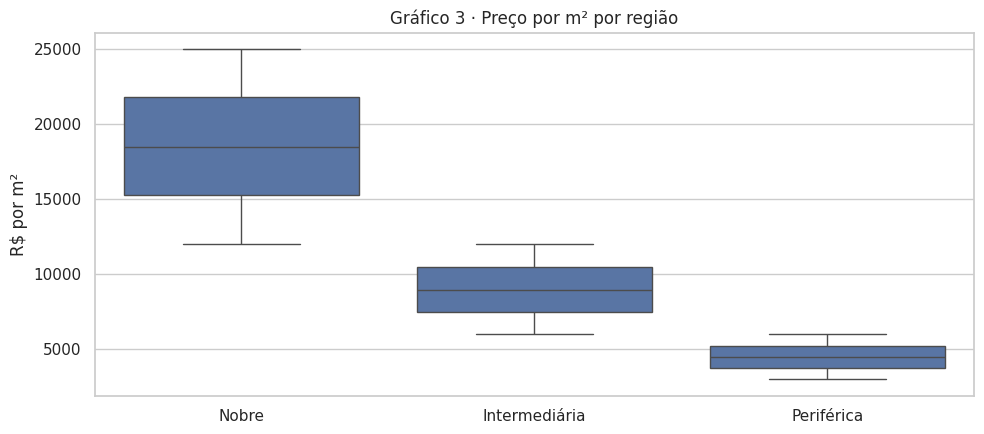

,count,mean,std,min,25%,50%,75%,max
regiao,,,,,,,,
Nobre,"6,039.00","18,508.96","3,778.19","12,000.62","15,261.79","18,519.58","21,835.28","24,998.04"
Intermediária,"9,581.00","8,977.78","1,723.39","6,000.63","7,514.18","8,984.45","10,476.44","11,999.53"
Periférica,"3,821.00","4,501.13",853.07,"3,001.41","3,770.79","4,512.26","5,226.53","5,997.21"


In [13]:
ordem_regioes = ["Nobre", "Intermediária", "Periférica"]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=limpo, x="regiao", y="preco_m2", order=ordem_regioes, ax=ax, showfliers=True)
ax.set_title("Gráfico 3 · Preço por m² por região")
ax.set_xlabel("")
ax.set_ylabel("R$ por m²")
plt.tight_layout()
plt.show()
limpo.groupby("regiao")["preco_m2"].describe().loc[ordem_regioes]

**Interpretação (Gráfico 3).** A região é o principal fator do preço por m²: cerca de R$ 18,5 mil na região Nobre, R$ 9 mil na Intermediária e R$ 4,5 mil na Periférica, uma diferença de **cerca de 4 vezes** entre os extremos. As caixas não se sobrepõem: as faixas são bem separadas (R$ 12–25 mil, 6–12 mil e 3–6 mil), exatamente as faixas usadas pelo generator. Dentro de cada região a distribuição é uniforme, sem caudas, e por isso não aparecem outliers depois da limpeza.

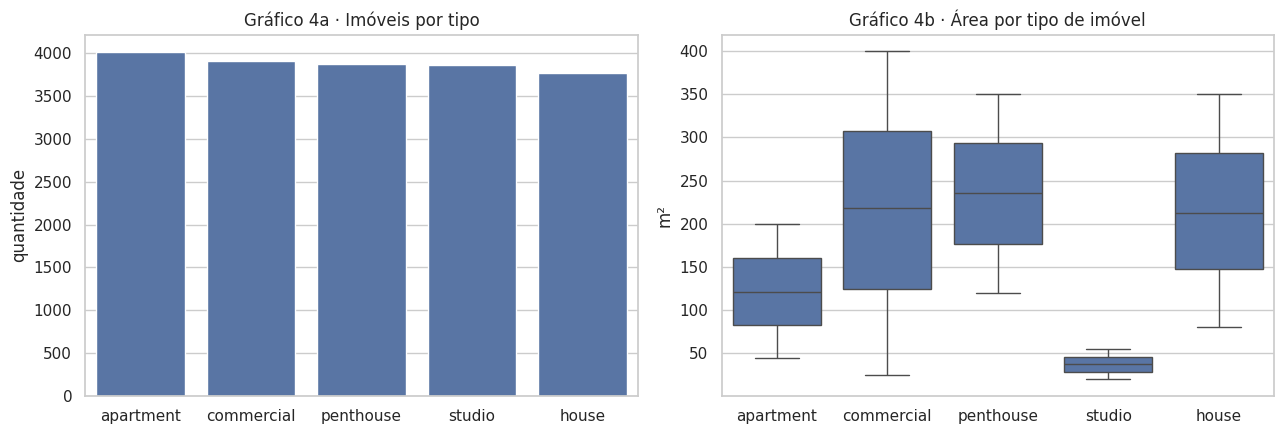

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
contagem = limpo["property_type"].value_counts()
sns.barplot(x=contagem.index, y=contagem.values, ax=axes[0], color="#4C72B0")
axes[0].set_title("Gráfico 4a · Imóveis por tipo")
axes[0].set_ylabel("quantidade")
sns.boxplot(data=limpo, x="property_type", y="area_m2", order=contagem.index, ax=axes[1])
axes[1].set_title("Gráfico 4b · Área por tipo de imóvel")
axes[1].set_ylabel("m²")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Interpretação (Gráfico 4).** Os cinco tipos de imóvel aparecem em quantidades praticamente iguais (cerca de 20% cada), porque o generator sorteia o tipo de forma uniforme. Em dados reais, apartamentos dominariam. A área muda muito por tipo: studios têm mediana próxima de 37 m², apartamentos de 120 m², e casas, salas comerciais e coberturas passam de 200 m². Isso explica por que studios têm o menor preço total mesmo com preço por m² parecido com o dos outros tipos (ver seção 3.5).

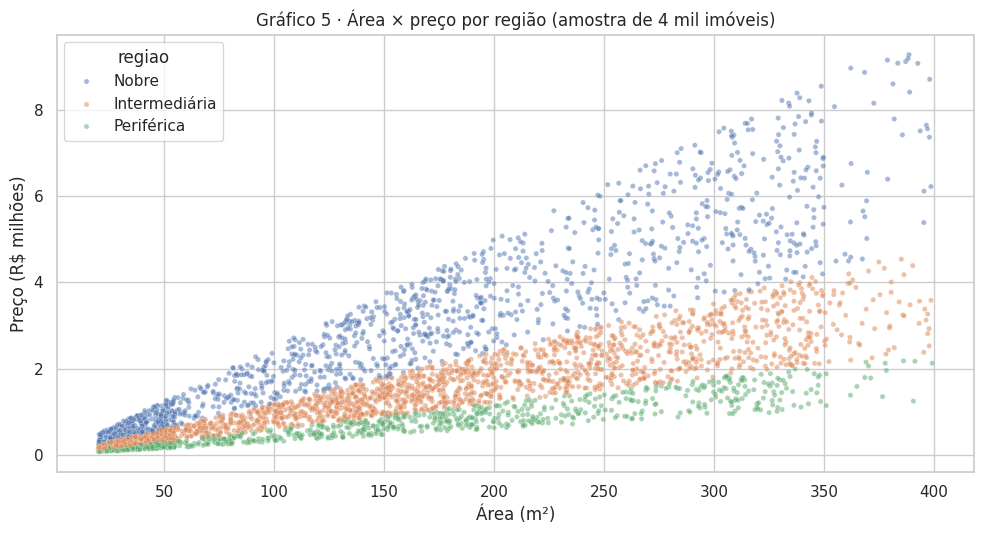

In [15]:
amostra = limpo.sample(min(4000, len(limpo)), random_state=42)
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=amostra, x="area_m2", y=amostra["price"] / 1e6, hue="regiao",
                hue_order=ordem_regioes, alpha=0.5, s=14, ax=ax)
ax.set_title("Gráfico 5 · Área × preço por região (amostra de 4 mil imóveis)")
ax.set_xlabel("Área (m²)")
ax.set_ylabel("Preço (R$ milhões)")
plt.tight_layout()
plt.show()

**Interpretação (Gráfico 5).** O preço cresce de forma linear com a área, mas em **três "leques" separados, um por região**: o que muda de uma região para outra é a inclinação, ou seja, o preço do m². Isso é uma **interação** entre área e região. Um modelo linear simples, que apenas soma efeitos, tem dificuldade para representar esse padrão; modelos baseados em árvores conseguem (seção 4.3).

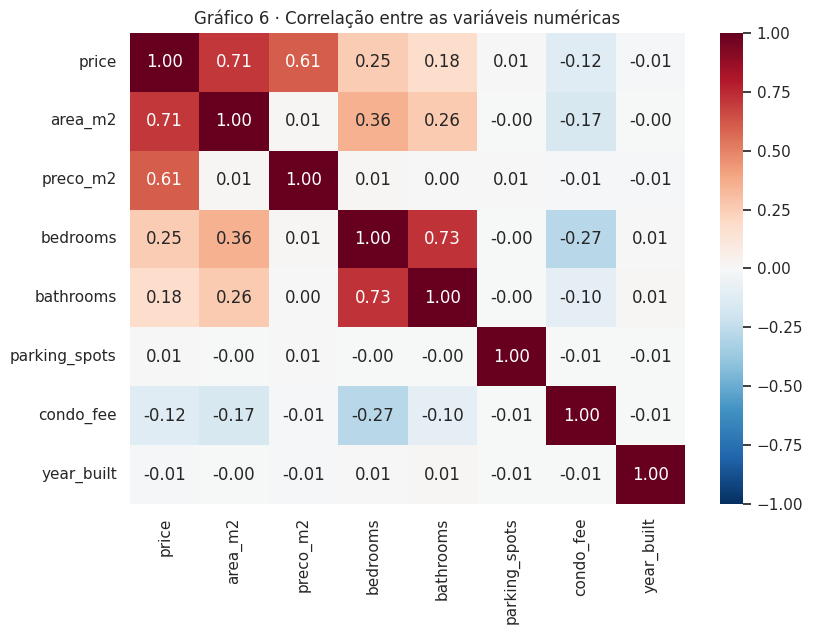

In [16]:
corr = limpo[["price", "area_m2", "preco_m2", "bedrooms", "bathrooms", "parking_spots", "condo_fee", "year_built"]].corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Gráfico 6 · Correlação entre as variáveis numéricas")
plt.tight_layout()
plt.show()

**Interpretação (Gráfico 6).** O preço tem correlação forte com a área (cerca de 0,7) e moderada com o preço por m² (cerca de 0,6). Quartos, banheiros, vagas, condomínio e ano de construção têm correlação **próxima de zero** com o preço e entre si, porque o generator sorteia essas variáveis de forma independente do preço. Conclusão para esta base: o que define o preço é **tamanho e localização**. Em dados reais, vagas e quartos teriam algum peso, o que é uma limitação a registrar.

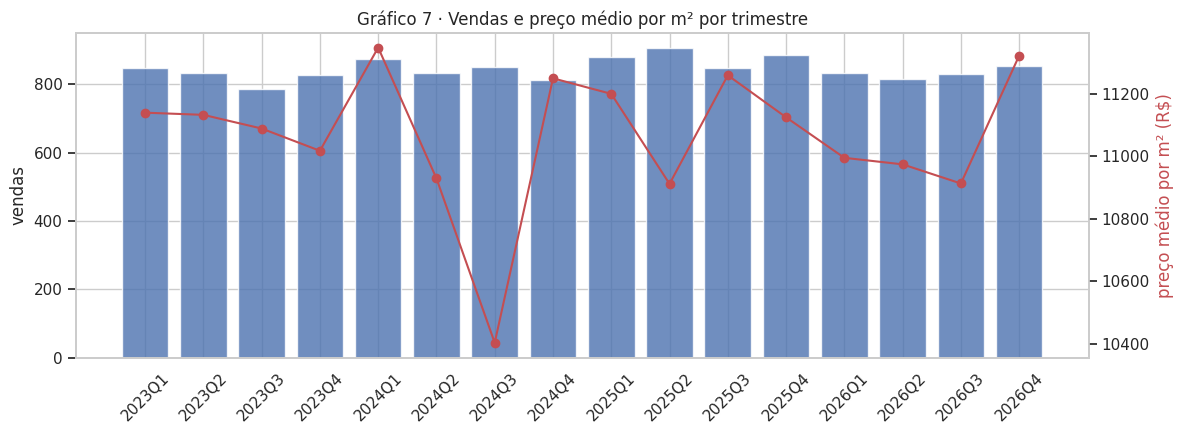

Imóveis vendidos: 69.5%


In [17]:
vendas = limpo[limpo["vendido"]].copy()
vendas["trimestre"] = vendas["sale_date"].dt.to_period("Q").astype(str)
por_trimestre = vendas.groupby("trimestre").agg(vendas=("record_id", "count"), preco_m2=("preco_m2", "mean"))

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(por_trimestre.index, por_trimestre["vendas"], color="#4C72B0", alpha=0.8)
ax1.set_ylabel("vendas")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(por_trimestre.index, por_trimestre["preco_m2"], color="#C44E52", marker="o")
ax2.set_ylabel("preço médio por m² (R$)", color="#C44E52")
ax2.grid(False)
ax1.set_title("Gráfico 7 · Vendas e preço médio por m² por trimestre")
plt.tight_layout()
plt.show()
print(f"Imóveis vendidos: {limpo['vendido'].mean():.1%}")

**Interpretação (Gráfico 7).** Cerca de 70% dos imóveis da base foram vendidos. As vendas se distribuem de forma uniforme entre 2023 e 2026 (perto de 800 por trimestre), **sem sazonalidade**, e o preço médio por m² fica estável em torno de R$ 11 mil: não há tendência de valorização ao longo do tempo na base sintética. O último trimestre inclui as vendas com data futura apontadas na seção 2.2.

<a id="3"></a>
## 3. Armazenamento, ETL e arquitetura analítica

### 3.1 Por que Data Warehouse (e não Data Lake)
Os dados são **predominantemente estruturados**: schema fixo de 20 colunas, tipos bem definidos e perguntas de negócio feitas sempre pelas mesmas dimensões (onde, quando, que tipo de imóvel, quais características). Esse é o cenário de um **Data Warehouse** com modelo dimensional. O único campo semiestruturado (`buyer_notes`) não é usado nas análises; ele e os CSVs brutos ficam preservados no repositório, que funciona como **área de entrada (staging)**: `data/raw` (bruto) → `data/processed` (tratado) → DW.

### 3.2 Arquitetura da solução

```
VM generator ──CSV──▶ GitHub data/raw ──GitHub Actions──▶ VM processing (R: limpeza)
                                                                 │ parquet
                                                                 ▼
                     GitHub data/processed ──git pull──▶ VM bigdata: ETL (Python, a cada 10 min)
                                                                 │
                                                                 ▼
             VM monitoring: Grafana ◀── PostgreSQL (esquema estrela) ──▶ Jupyter / Colab (este notebook)
```

### 3.3 Modelo dimensional (esquema estrela)

| Tabela | Tipo | Conteúdo | Hierarquia |
|---|---|---|---|
| `fato_imovel` | fato | preço, área, preço por m², condomínio, vendido | grão: 1 imóvel |
| `dim_localizacao` | dimensão | bairro, região, cidade, estado | bairro → região → cidade → estado |
| `dim_tempo` | dimensão | data da venda; membro "Sem data" para não vendidos | data → mês → trimestre → ano |
| `dim_tipo_imovel` | dimensão | tipo em inglês e português | — |
| `dim_caracteristicas` | dimensão | quartos, banheiros, vagas, mobiliado, faixa de área e de idade | — |
| `etl_carga` | controle | arquivo, linhas lidas/inseridas/ignoradas, horário | evidência do ETL |

### 3.4 Processo ETL
* **Extração:** o ETL (`scripts/etl.py`) faz `git pull` e lista os parquets que ainda não constam em `etl_carga`.
* **Transformação:** deriva região, preço por m², faixas de área e idade e a dimensão tempo; descarta nome de vendedor e comprador (LGPD).
* **Carga:** insere os membros novos das dimensões e depois a fato, numa transação por arquivo. Cada arquivo entra uma única vez.

No modo `dw` as consultas abaixo vão ao PostgreSQL real. No modo `github` a mesma transformação é refeita aqui e o esquema estrela é montado em DuckDB.

In [18]:
TIPO_PT = {"apartment": "Apartamento", "house": "Casa", "studio": "Studio",
           "commercial": "Comercial", "penthouse": "Cobertura"}
MESES = ["Janeiro", "Fevereiro", "Março", "Abril", "Maio", "Junho", "Julho",
         "Agosto", "Setembro", "Outubro", "Novembro", "Dezembro"]


def faixa_area(a):
    return ("até 40 m²" if a <= 40 else "41 a 80 m²" if a <= 80 else "81 a 120 m²" if a <= 120
            else "121 a 200 m²" if a <= 200 else "acima de 200 m²")


def faixa_idade(ano):
    if pd.isna(ano):
        return "Desconhecida"
    idade = pd.Timestamp.today().year - ano
    return ("até 10 anos" if idade <= 10 else "11 a 20 anos" if idade <= 20 else "21 a 30 anos" if idade <= 30
            else "31 a 40 anos" if idade <= 40 else "mais de 40 anos")


def montar_dw_em_memoria():
    """Réplica do ETL (scripts/etl.py) em pandas + DuckDB, para rodar sem a VM."""
    partes = []
    for i, nome in enumerate(arquivos_processed, start=1):
        p = pd.read_parquet(baixar("data/processed", nome))
        p["id_carga"] = i
        partes.append(p)
    t = pd.concat(partes, ignore_index=True).drop_duplicates("record_id")
    t["sale_date"] = pd.to_datetime(t["sale_date"], errors="coerce")

    loc = pd.DataFrame([(n, REGIAO_PT[z], "São Paulo", "SP", la, lo) for n, la, lo, z in BAIRROS],
                       columns=["bairro", "regiao", "cidade", "estado", "latitude", "longitude"])
    loc.insert(0, "sk_localizacao", range(1, len(loc) + 1))

    tipo = pd.DataFrame(sorted(TIPO_PT.items()), columns=["tipo", "tipo_pt"])
    tipo.insert(0, "sk_tipo", range(1, len(tipo) + 1))

    datas = t["sale_date"].dropna().dt.normalize().drop_duplicates()
    tempo = pd.DataFrame({
        "sk_tempo": datas.dt.strftime("%Y%m%d").astype(int), "data": datas.dt.date, "ano": datas.dt.year,
        "trimestre": datas.dt.quarter, "mes": datas.dt.month, "nome_mes": datas.dt.month.map(lambda m: MESES[m - 1]),
    })
    tempo = pd.concat([pd.DataFrame([{"sk_tempo": 0, "nome_mes": "Sem data"}]), tempo], ignore_index=True)

    t["faixa_area"] = t["area_m2"].map(faixa_area)
    t["faixa_idade"] = t["year_built"].map(faixa_idade)
    chave_carac = ["bedrooms", "bathrooms", "parking_spots", "furnished", "faixa_area", "faixa_idade"]
    carac = t[chave_carac].drop_duplicates().reset_index(drop=True)
    carac.insert(0, "sk_caracteristicas", range(1, len(carac) + 1))

    fato = (t.merge(loc[["sk_localizacao", "bairro"]], left_on="neighborhood", right_on="bairro")
             .merge(tipo[["sk_tipo", "tipo"]], left_on="property_type", right_on="tipo")
             .merge(carac, on=chave_carac, how="left"))
    fato["sk_tempo"] = fato["sale_date"].dt.strftime("%Y%m%d").fillna("0").astype(int)
    fato = pd.DataFrame({
        "record_id": fato["record_id"], "sk_localizacao": fato["sk_localizacao"], "sk_tempo": fato["sk_tempo"],
        "sk_tipo": fato["sk_tipo"], "sk_caracteristicas": fato["sk_caracteristicas"], "id_carga": fato["id_carga"],
        "vendido": fato["sale_date"].notna(), "preco": fato["price"], "area_m2": fato["area_m2"],
        "preco_m2": (fato["price"] / fato["area_m2"]).round(2), "condominio": fato["condo_fee"],
        "ano_construcao": fato["year_built"], "latitude": fato["latitude"], "longitude": fato["longitude"],
    })
    carac = carac.rename(columns={"bedrooms": "quartos", "bathrooms": "banheiros",
                                  "parking_spots": "vagas", "furnished": "mobiliado"})

    con = duckdb.connect()
    con.execute("CREATE SCHEMA dw")
    for nome, df in {"dim_localizacao": loc, "dim_tipo_imovel": tipo, "dim_tempo": tempo,
                     "dim_caracteristicas": carac, "fato_imovel": fato}.items():
        con.register("tmp", df)
        con.execute(f"CREATE TABLE dw.{nome} AS SELECT * FROM tmp")
        con.unregister("tmp")
    con.execute("""
        CREATE VIEW dw.vw_imoveis AS
        SELECT f.record_id, l.bairro, l.regiao, l.cidade, l.estado, t.tipo, t.tipo_pt,
               c.quartos, c.banheiros, c.vagas, c.mobiliado, c.faixa_area, c.faixa_idade,
               tp.data AS data_venda, tp.ano, tp.trimestre, tp.mes, tp.nome_mes,
               f.vendido, f.preco, f.area_m2, f.preco_m2, f.condominio, f.ano_construcao,
               f.latitude, f.longitude, f.id_carga
        FROM dw.fato_imovel f
        JOIN dw.dim_localizacao l USING (sk_localizacao)
        JOIN dw.dim_tipo_imovel t USING (sk_tipo)
        JOIN dw.dim_caracteristicas c USING (sk_caracteristicas)
        JOIN dw.dim_tempo tp USING (sk_tempo)
    """)
    return con


if MODO == "dw":
    from sqlalchemy import create_engine
    engine = create_engine("postgresql+psycopg:///" + os.getenv("DW_DSN", "dbname=realestate").split("dbname=")[-1])
else:
    con = montar_dw_em_memoria()


def consulta(sql):
    """Executa SQL no Data Warehouse ativo (PostgreSQL no modo dw, DuckDB no modo github)."""
    df = pd.read_sql(sql, engine) if MODO == "dw" else con.sql(sql).df()
    for col in df.columns:  # NUMERIC do PostgreSQL chega como Decimal
        if df[col].dtype == object and df[col].map(lambda v: isinstance(v, Decimal)).any():
            df[col] = df[col].astype(float)
    return df


consulta("""
    SELECT 'fato_imovel' AS tabela, COUNT(*) AS linhas FROM dw.fato_imovel
    UNION ALL SELECT 'dim_localizacao', COUNT(*) FROM dw.dim_localizacao
    UNION ALL SELECT 'dim_tempo', COUNT(*) FROM dw.dim_tempo
    UNION ALL SELECT 'dim_tipo_imovel', COUNT(*) FROM dw.dim_tipo_imovel
    UNION ALL SELECT 'dim_caracteristicas', COUNT(*) FROM dw.dim_caracteristicas
""")

,tabela,linhas
0,fato_imovel,19441
1,dim_localizacao,45
2,dim_tempo,1345
3,dim_tipo_imovel,5
4,dim_caracteristicas,2714


In [19]:
if MODO == "dw":
    display(consulta("""SELECT id, arquivo, finalizado_em, linhas_lidas, linhas_inseridas, linhas_ignoradas, status
                         FROM dw.etl_carga ORDER BY id DESC LIMIT 10"""))
else:
    print("Modo github: o histórico de cargas (dw.etl_carga) só existe no Data Warehouse real da VM bigdata.")

,id,arquivo,finalizado_em,linhas_lidas,linhas_inseridas,linhas_ignoradas,status
0,11,listings_20261112_000743_clean.parquet,2026-11-12 00:15:22.629662+00:00,137,137,0,concluída
1,10,listings_20261111_233849_clean.parquet,2026-11-11 23:39:37.910363+00:00,157,157,0,concluída
2,9,listings_20261111_230844_clean.parquet,2026-11-11 23:10:25.768528+00:00,148,148,0,concluída
3,8,listings_20261111_000000_clean.parquet,2026-11-11 23:10:23.940992+00:00,18174,18174,0,concluída
4,7,listings_20261111_011624_clean.parquet,2026-11-11 01:17:34.147810+00:00,159,159,0,concluída
5,6,listings_20261111_004622_clean.parquet,2026-11-11 01:17:34.046617+00:00,143,143,0,concluída
6,5,listings_20261111_001618_clean.parquet,2026-11-11 01:17:33.931490+00:00,165,165,0,concluída
7,4,listings_20261110_171513_clean.parquet,2026-11-11 01:17:33.874495+00:00,62,62,0,concluída
8,3,listings_20261110_165046_clean.parquet,2026-11-11 01:17:33.829074+00:00,51,51,0,concluída
9,2,listings_20261006_231642_clean.parquet,2026-11-11 01:17:33.736134+00:00,127,127,0,concluída


### 3.5 Operações OLAP
Todas as consultas usam a view `dw.vw_imoveis`, que junta a fato com as dimensões (o cubo "achatado").

**Roll-up**: sobe na hierarquia de localização, de bairro para região e para o total geral.

In [20]:
rollup = consulta("""
    SELECT COALESCE(regiao, 'TOTAL GERAL') AS regiao,
           COALESCE(bairro, CASE WHEN regiao IS NULL THEN '' ELSE '(total da região)' END) AS bairro,
           COUNT(*) AS imoveis,
           ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis
    GROUP BY ROLLUP (regiao, bairro)
    ORDER BY GROUPING(regiao), regiao, GROUPING(bairro) DESC, preco_m2_medio DESC
""")
rollup[(rollup["bairro"].isin(["", "(total da região)"]))]

,regiao,bairro,imoveis,preco_m2_medio
0,Intermediária,(total da região),9581,"8,978.00"
23,Nobre,(total da região),6039,"18,509.00"
38,Periférica,(total da região),3821,"4,501.00"
48,TOTAL GERAL,,19441,"11,059.00"


**Drill-down**: desce na hierarquia de tempo, de ano para trimestre e de trimestre para mês (só imóveis vendidos).

In [21]:
por_ano = consulta("""
    SELECT ano, COUNT(*) AS vendas, ROUND(SUM(preco) / 1e6, 1) AS valor_milhoes, ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis WHERE vendido GROUP BY ano ORDER BY ano
""")
ultimo_ano = int(por_ano["ano"].max())
por_trimestre_dw = consulta(f"""
    SELECT ano, trimestre, COUNT(*) AS vendas, ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis WHERE vendido AND ano = {ultimo_ano} GROUP BY ano, trimestre ORDER BY trimestre
""")
por_mes = consulta(f"""
    SELECT ano, trimestre, mes, nome_mes, COUNT(*) AS vendas
    FROM dw.vw_imoveis WHERE vendido AND ano = {ultimo_ano} AND trimestre = 1
    GROUP BY ano, trimestre, mes, nome_mes ORDER BY mes
""")
display(por_ano, por_trimestre_dw, por_mes)

,ano,vendas,valor_milhoes,preco_m2_medio
0,2023,3295,"6,078.50","11,095.00"
1,2024,3371,"6,065.30","10,983.00"
2,2025,3520,"6,396.80","11,121.00"
3,2026,3335,"6,197.70","11,054.00"


,ano,trimestre,vendas,preco_m2_medio
0,2026,1,834,"10,995.00"
1,2026,2,815,"10,975.00"
2,2026,3,831,"10,913.00"
3,2026,4,855,"11,322.00"


,ano,trimestre,mes,nome_mes,vendas
0,2026,1,1,Janeiro,279
1,2026,1,2,Fevereiro,292
2,2026,1,3,Março,263


**Slice**: fixa uma dimensão (somente apartamentos) e analisa as demais.

In [22]:
consulta("""
    SELECT regiao, COUNT(*) AS apartamentos, ROUND(AVG(preco), 0) AS preco_medio, ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis WHERE tipo_pt = 'Apartamento'
    GROUP BY regiao ORDER BY preco_m2_medio DESC
""")

,regiao,apartamentos,preco_medio,preco_m2_medio
0,Nobre,1263,"2,266,113.00","18,625.00"
1,Intermediária,1947,"1,089,836.00","8,933.00"
2,Periférica,807,"545,844.00","4,482.00"


**Dice**: recorta várias dimensões ao mesmo tempo (região Nobre, 2 a 3 quartos, vendidos no último ano).

In [23]:
consulta(f"""
    SELECT bairro, COUNT(*) AS vendas, ROUND(AVG(preco), 0) AS preco_medio, ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis
    WHERE regiao = 'Nobre' AND quartos BETWEEN 2 AND 3 AND vendido AND ano = {ultimo_ano}
    GROUP BY bairro ORDER BY preco_m2_medio DESC
""")

,bairro,vendas,preco_medio,preco_m2_medio
0,Jardins,20,"3,866,814.00","19,674.00"
1,Perdizes,20,"4,579,528.00","19,397.00"
2,Pinheiros,26,"3,534,162.00","19,282.00"
3,Paraíso,18,"3,857,532.00","19,026.00"
4,Higienópolis,22,"3,603,703.00","18,807.00"
5,Alto de Pinheiros,19,"3,195,328.00","18,684.00"
6,Campo Belo,21,"3,064,859.00","18,626.00"
7,Itaim Bibi,13,"3,617,808.00","18,350.00"
8,Moema,20,"3,039,113.00","18,338.00"
9,Consolação,18,"3,952,765.00","18,245.00"


**Pivot / CUBE**: todas as combinações de tipo × região, com subtotais, giradas em tabela.

In [24]:
cubo = consulta("""
    SELECT COALESCE(tipo_pt, 'TODOS') AS tipo, COALESCE(regiao, 'TODAS') AS regiao,
           ROUND(AVG(preco_m2), 0) AS preco_m2_medio
    FROM dw.vw_imoveis
    GROUP BY CUBE (tipo_pt, regiao)
""")
cubo.pivot(index="tipo", columns="regiao", values="preco_m2_medio")[ordem_regioes + ["TODAS"]]

regiao,Nobre,Intermediária,Periférica,TODAS
tipo,,,,
Apartamento,"18,625.00","8,933.00","4,482.00","11,086.00"
Casa,"18,545.00","9,017.00","4,513.00","11,223.00"
Cobertura,"18,445.00","8,969.00","4,510.00","11,046.00"
Comercial,"18,402.00","9,003.00","4,467.00","11,093.00"
Studio,"18,525.00","8,968.00","4,532.00","10,848.00"
TODOS,"18,509.00","8,978.00","4,501.00","11,059.00"


**Interpretação das operações OLAP.**
* **Roll-up:** o m² da região Nobre custa cerca do dobro da Intermediária e cerca de 4 vezes o da Periférica; dentro de cada região os bairros são parecidos entre si.
* **Drill-down:** o volume de vendas e o preço por m² se mantêm estáveis de ano para ano, de trimestre para trimestre e de mês para mês.
* **Slice (apartamentos):** a mesma hierarquia de regiões se repete quando olhamos só um tipo de imóvel.
* **Dice:** nos bairros nobres, imóveis de 2 a 3 quartos vendidos no último ano têm preço por m² entre cerca de R$ 17 e 20 mil.
* **Cubo:** dentro de uma mesma região, todos os tipos têm preço por m² muito parecido. O tipo de imóvel muda o **preço total** (pela área típica), mas **não o preço do m²**.

**Para a imobiliária:** a precificação deve partir da **localização** (preço do m² da região e do bairro) multiplicada pela **área**; o tipo de imóvel entra pela área, e não como um prêmio no m².

<a id="4"></a>
## 4. Data Mining e Machine Learning

A partir daqui os dados vêm do Data Warehouse (`dw.vw_imoveis`).

In [25]:
imoveis = consulta("SELECT * FROM dw.vw_imoveis")
print(f"{len(imoveis):,} imóveis no DW")

19,441 imóveis no DW


### 4.1 Detecção de outliers (Data Mining)
Regra do intervalo interquartil (IQR) aplicada ao preço por m² **dentro de cada região**, já que cada região tem um patamar de preço diferente.

In [26]:
def marcar_outliers(grupo):
    q1, q3 = grupo.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (grupo < q1 - 1.5 * iqr) | (grupo > q3 + 1.5 * iqr)


imoveis["outlier_m2"] = imoveis.groupby("regiao")["preco_m2"].transform(marcar_outliers)
imoveis.groupby("regiao")["outlier_m2"].agg(outliers="sum", percentual="mean").loc[ordem_regioes]

,outliers,percentual
regiao,,
Nobre,0,0.00
Intermediária,0,0.00
Periférica,0,0.00


**Interpretação.** Pela regra do IQR, **nenhum imóvel é outlier** dentro da sua região: na base sintética o preço do m² é sorteado de forma uniforme numa faixa fechada, sem caudas, e os valores absurdos (negativos ou zerados) já foram removidos na limpeza. Em dados reais esperaríamos outliers (imóveis de alto luxo, erros de digitação) e esta etapa ganharia importância.

### 4.2 Agrupamento de bairros (K-Means)
**Objetivo:** descobrir grupos de bairros com perfil parecido sem usar a região como entrada, e ver se os grupos encontrados coincidem com a classificação Nobre / Intermediária / Periférica.

**Variáveis por bairro:** preço médio por m², área média, condomínio médio e taxa de venda, padronizadas (z-score) porque estão em escalas diferentes. O número de grupos `k` é escolhido pelo **coeficiente de silhueta**.

Silhueta por k: {2: np.float64(0.238), 3: np.float64(0.285), 4: np.float64(0.287), 5: np.float64(0.272), 6: np.float64(0.253)}
k escolhido: 4


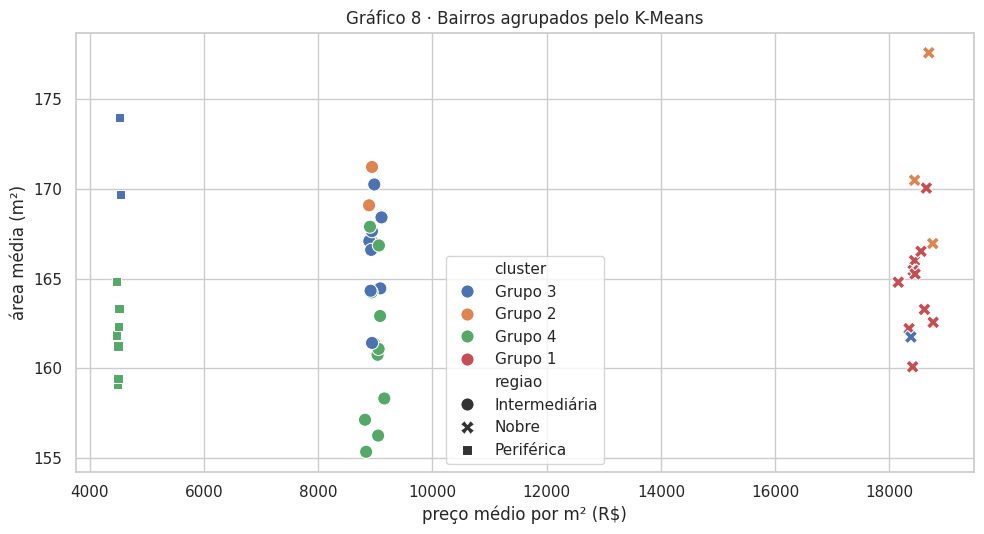

regiao,Nobre,Intermediária,Periférica
cluster,,,
Grupo 1,10,0,0
Grupo 2,3,3,0
Grupo 3,1,8,2
Grupo 4,0,11,7


In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

perfil = imoveis.groupby("bairro").agg(
    preco_m2_medio=("preco_m2", "mean"), area_media=("area_m2", "mean"),
    condominio_medio=("condominio", "mean"), taxa_venda=("vendido", "mean"), regiao=("regiao", "first"),
)
X_bairros = StandardScaler().fit_transform(perfil[["preco_m2_medio", "area_media", "condominio_medio", "taxa_venda"]])

silhuetas = {k: silhouette_score(X_bairros, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_bairros))
             for k in range(2, 7)}
k_escolhido = max(silhuetas, key=silhuetas.get)
print("Silhueta por k:", {k: round(v, 3) for k, v in silhuetas.items()})
print("k escolhido:", k_escolhido)

perfil["cluster"] = KMeans(n_clusters=k_escolhido, n_init=10, random_state=42).fit_predict(X_bairros)
ordem = perfil.groupby("cluster")["preco_m2_medio"].mean().sort_values(ascending=False).index
perfil["cluster"] = perfil["cluster"].map({c: f"Grupo {i + 1}" for i, c in enumerate(ordem)})

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.scatterplot(data=perfil, x="preco_m2_medio", y="area_media", hue="cluster", style="regiao", s=90, ax=ax)
ax.set_title("Gráfico 8 · Bairros agrupados pelo K-Means")
ax.set_xlabel("preço médio por m² (R$)")
ax.set_ylabel("área média (m²)")
plt.tight_layout()
plt.show()
pd.crosstab(perfil["cluster"], perfil["regiao"])[ordem_regioes]

**Interpretação (Gráfico 8).** O coeficiente de silhueta fica em torno de 0,3 para todos os valores de `k`, o que indica uma separação **moderada** entre grupos. Mesmo sem receber a região como entrada, o K-Means **reencontrou os patamares de preço do m²**: no gráfico, os bairros formam três colunas (perto de R$ 4,5 mil, 9 mil e 18,5 mil por m²) que coincidem com as regiões Periférica, Intermediária e Nobre, e os grupos de maior preço reúnem só bairros nobres. Dentro de uma mesma coluna, o algoritmo separa os bairros pela área média e pela taxa de venda, por isso alguns grupos misturam bairros de regiões vizinhas. Essas variáveis variam pouco entre bairros (são sorteadas da mesma forma pelo generator), o que explica a silhueta apenas moderada. Conclusão: **o preço do m², ou seja, a localização, é o eixo principal do mercado**; o resto é variação pequena.

### 4.3 Regressão: prever o preço do imóvel

**Tarefa:** regressão (o alvo, `preco`, é numérico contínuo).

**Variáveis de entrada:** área, quartos, banheiros, vagas, condomínio, ano de construção, mobiliado, tipo, região e bairro. Ficam de fora `preco_m2` (é derivado do próprio preço, causaria vazamento) e a data de venda (não se sabe antes de anunciar).

**Modelos:**
* **Regressão Linear** como linha de base: simples e interpretável.
* **Random Forest**: captura interações (por exemplo, o efeito da área depende do bairro) e relações não lineares, que é exatamente como o preço é formado (área × preço do m² da região).
  Hiperparâmetros: 100 árvores, mínimo de 5 imóveis por folha e metade das variáveis por divisão (`max_features=0.5`). Essa configuração foi escolhida comparando tempo e erro: ficou cerca de 6 vezes mais rápida que 150 árvores com folhas de 2 imóveis, com erro igual ou menor.

**Avaliação:** 80% treino / 20% teste, com MAE, RMSE, MAPE e R².

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

NUMERICAS = ["area_m2", "quartos", "banheiros", "vagas", "condominio", "ano_construcao"]
CATEGORICAS = ["tipo_pt", "regiao", "bairro", "mobiliado"]

base_ml = imoveis.dropna(subset=NUMERICAS + CATEGORICAS + ["preco"]).copy()
base_ml["mobiliado"] = base_ml["mobiliado"].astype(str)
X = base_ml[NUMERICAS + CATEGORICAS]
y = base_ml["preco"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Treino: {len(X_treino):,} | Teste: {len(X_teste):,}")

preparo = ColumnTransformer([
    ("num", "passthrough", NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
])
modelos = {
    "Regressão Linear": Pipeline([("prep", preparo), ("modelo", LinearRegression())]),
    "Random Forest": Pipeline([("prep", preparo),
                               ("modelo", RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                                                max_features=0.5, n_jobs=-1, random_state=42))]),
}

resultados, previsoes = [], {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)
    previsoes[nome] = previsto
    resultados.append({
        "modelo": nome,
        "MAE (R$)": mean_absolute_error(y_teste, previsto),
        "RMSE (R$)": mean_squared_error(y_teste, previsto) ** 0.5,
        "MAPE": mean_absolute_percentage_error(y_teste, previsto),
        "R²": r2_score(y_teste, previsto),
    })
metricas = pd.DataFrame(resultados).set_index("modelo")
metricas.style.format({"MAE (R$)": "R$ {:,.0f}", "RMSE (R$)": "R$ {:,.0f}", "MAPE": "{:.1%}", "R²": "{:.3f}"})

Treino: 15,404 | Teste: 3,851


,MAE (R$),RMSE (R$),MAPE,R²
modelo,,,,
Regressão Linear,"R$ 535,910","R$ 733,576",67.8%,0.802
Random Forest,"R$ 316,327","R$ 485,287",18.1%,0.913


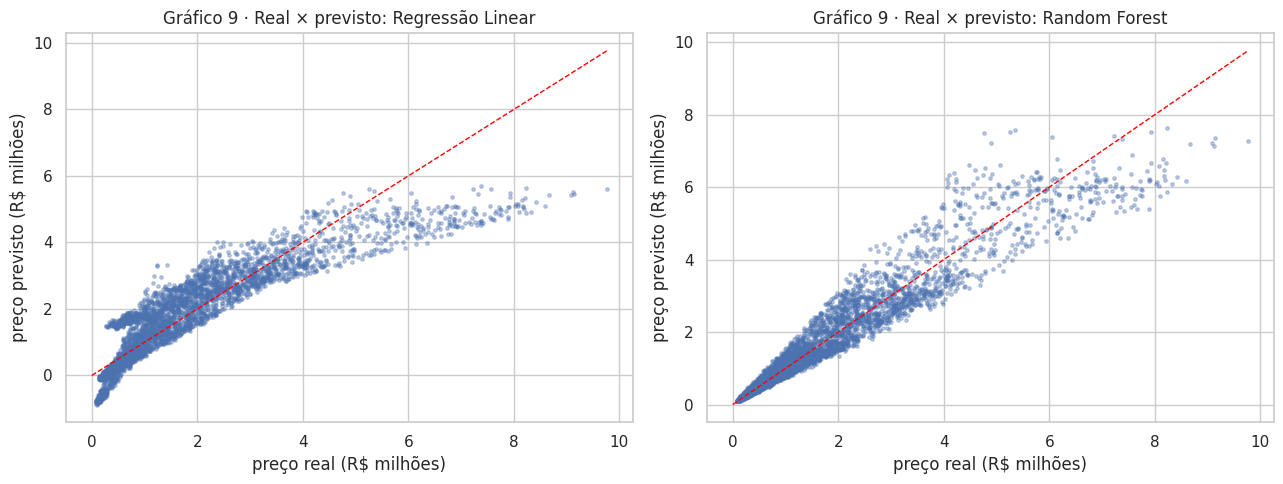

Regressão Linear: menor previsão R$ -874,234; previsões negativas: 353


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, previsto) in zip(axes, previsoes.items()):
    ax.scatter(y_teste / 1e6, previsto / 1e6, s=6, alpha=0.35)
    limite = max(y_teste.max(), previsto.max()) / 1e6
    ax.plot([0, limite], [0, limite], color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Gráfico 9 · Real × previsto: {nome}")
    ax.set_xlabel("preço real (R$ milhões)")
    ax.set_ylabel("preço previsto (R$ milhões)")
plt.tight_layout()
plt.show()
linear = previsoes["Regressão Linear"]
print(f"Regressão Linear: menor previsão R$ {linear.min():,.0f}; previsões negativas: {(linear < 0).sum()}")

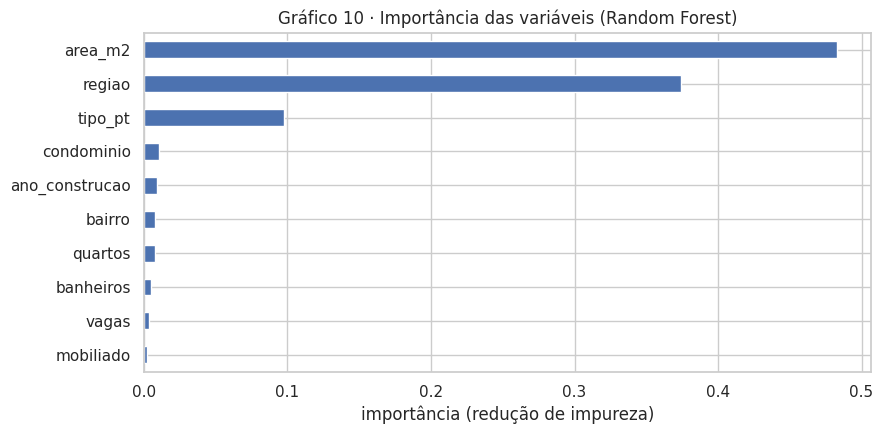

,% da importância
area_m2,48.30
regiao,37.40
tipo_pt,9.80
condominio,1.00
ano_construcao,0.90
bairro,0.80
quartos,0.80
banheiros,0.50
vagas,0.30
mobiliado,0.20


In [30]:
rf = modelos["Random Forest"]
nomes = rf.named_steps["prep"].get_feature_names_out()


def variavel_original(coluna):
    """'cat__bairro_Moema' → 'bairro'; 'num__area_m2' → 'area_m2'."""
    _, nome = coluna.split("__", 1)
    return next((c for c in CATEGORICAS if nome.startswith(c + "_")), nome)


# Soma as colunas one-hot de volta na variável original (ex.: todos os bairros em "bairro")
importancias = (pd.Series(rf.named_steps["modelo"].feature_importances_, index=nomes)
                .groupby(variavel_original).sum().sort_values())

fig, ax = plt.subplots(figsize=(9, 4.5))
importancias.plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Gráfico 10 · Importância das variáveis (Random Forest)")
ax.set_xlabel("importância (redução de impureza)")
plt.tight_layout()
plt.show()
(importancias.sort_values(ascending=False) * 100).round(1).rename("% da importância").to_frame()

**Interpretação (Gráficos 9 e 10).**
* A **Random Forest é bem melhor** que a Regressão Linear: R² em torno de 0,90 contra 0,80, erro médio absoluto (MAE) cerca de 40% menor e MAPE em torno de 18% contra cerca de 68%.
* O MAPE alto da regressão linear vem dos **imóveis baratos**: como o modelo só soma efeitos, ele não representa a interação área × região (Gráfico 5) e erra muito, em proporção, nos imóveis pequenos e periféricos. No Gráfico 9 isso aparece como pontos espalhados e até previsões negativas na parte de baixo.
* **Importância das variáveis:** área (cerca de 55%) e região (cerca de 40%) explicam quase tudo. O bairro acrescenta pouco porque a região já carrega essa informação. Quartos, vagas, idade e mobiliado somam poucos pontos percentuais, confirmando a análise de correlação.
* **Por que o erro não cai abaixo de cerca de 18%:** o generator sorteia o preço do m² de forma aleatória dentro da faixa da região (por exemplo, de R$ 12 mil a R$ 25 mil na Nobre). Essa parte é ruído puro, e nenhum modelo consegue prevê-la; é o "teto" desta base.
* **Cuidado:** as métricas refletem as regras do generator. Com dados reais o desempenho seria menor e outras variáveis (vagas, idade, infraestrutura do entorno) passariam a pesar.

### 4.4 Do modelo à decisão: imóveis abaixo do valor previsto
Para não avaliar o modelo nos mesmos dados em que ele foi treinado, o preço "justo" de cada imóvel disponível é estimado com **validação cruzada** (cada imóvel é previsto por um modelo que não o viu no treino).

In [31]:
from sklearn.model_selection import cross_val_predict

base_ml["preco_previsto"] = cross_val_predict(modelos["Random Forest"], X, y, cv=5, n_jobs=1)
base_ml["desconto"] = 1 - base_ml["preco"] / base_ml["preco_previsto"]
oportunidades = (base_ml[~base_ml["vendido"]]
                 .sort_values("desconto", ascending=False)
                 [["bairro", "regiao", "tipo_pt", "area_m2", "preco", "preco_previsto", "desconto"]]
                 .head(10))
abaixo = (~base_ml["vendido"]) & (base_ml["desconto"] >= 0.2)
print(f"Imóveis disponíveis com preço 20% ou mais abaixo do previsto: {abaixo.sum():,}")
print("Por região:", base_ml.loc[abaixo, "regiao"].value_counts(normalize=True).round(3).to_dict())
oportunidades.style.format({"area_m2": "{:.0f}", "preco": "R$ {:,.0f}", "preco_previsto": "R$ {:,.0f}", "desconto": "{:.0%}"})

Imóveis disponíveis com preço 20% ou mais abaixo do previsto: 1,232
Por região: {'Intermediária': 0.512, 'Nobre': 0.303, 'Periférica': 0.185}


,bairro,regiao,tipo_pt,area_m2,preco,preco_previsto,desconto
15777,Tatuapé,Intermediária,Comercial,48,"R$ 291,181","R$ 562,984",48%
11820,Paraíso,Nobre,Comercial,34,"R$ 410,298","R$ 789,634",48%
15743,Tatuapé,Intermediária,Comercial,68,"R$ 416,267","R$ 734,438",43%
11753,Paraíso,Nobre,Casa,84,"R$ 1,014,328","R$ 1,747,339",42%
11722,Paraíso,Nobre,Apartamento,129,"R$ 1,574,649","R$ 2,673,561",41%
15007,Sapopemba,Periférica,Apartamento,45,"R$ 143,167","R$ 241,617",41%
9378,Lapa,Intermediária,Studio,21,"R$ 124,924","R$ 209,458",40%
11740,Paraíso,Nobre,Apartamento,97,"R$ 1,220,853","R$ 2,043,408",40%
17220,Vila Madalena,Nobre,Casa,165,"R$ 1,989,334","R$ 3,285,349",39%
15625,Tatuapé,Intermediária,Cobertura,218,"R$ 1,321,146","R$ 2,167,446",39%


<a id="5"></a>
## 5. Processamento distribuído: Apache Spark e o ecossistema Hadoop

### 5.1 O uso de Spark se justifica?
Com algumas dezenas de milhares de registros, **pandas resolve tudo em segundos** numa única máquina, então o Spark não é necessário *hoje*. Ele passa a se justificar quando:

* o generator roda por meses (≈ 6 mil registros/dia → milhões por ano) ou a base é trocada por dados reais de portais;
* chegam fontes variadas (anúncios em texto, imagens, logs de acesso) que não cabem na memória de uma máquina;
* o processamento precisa ser paralelo e tolerante a falhas.

Por isso a mesma análise é feita abaixo com **Spark em modo local** (`local[*]`): o código é idêntico ao que rodaria num cluster; para escalar, muda apenas o `master` (por exemplo, YARN) e o local dos arquivos (HDFS ou S3).

### 5.2 Papel dos componentes

| Componente | Papel | Equivalente nesta solução | Num cluster real |
|---|---|---|---|
| **HDFS** | armazenamento distribuído em blocos replicados | arquivos parquet no repositório / disco da VM | parquets particionados por data no HDFS |
| **YARN** | gerencia recursos e agenda os jobs do cluster | systemd timer + Spark `local[*]` | Spark com `master=yarn` |
| **MapReduce** | processamento paralelo map → shuffle → reduce | `map` + `reduceByKey` no Spark (abaixo) | jobs Spark (que substituem MapReduce) |
| **Hive** | SQL sobre arquivos do HDFS | Spark SQL / PostgreSQL | Spark SQL com metastore do Hive |

In [32]:
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .master("local[*]")
         .appName("PI-BigData-Imoveis")
         .config("spark.driver.memory", os.getenv("SPARK_DRIVER_MEMORY", "1g"))
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| núcleos disponíveis:", spark.sparkContext.defaultParallelism)

caminhos = [baixar("data/processed", n) for n in arquivos_processed]
sdf = spark.read.parquet(*caminhos)
print(f"{sdf.count():,} registros lidos de {len(caminhos)} arquivos parquet em {sdf.rdd.getNumPartitions()} partições")
sdf.printSchema()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 00:18:31 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.3 | núcleos disponíveis: 2


19,441 registros lidos de 11 arquivos parquet em 2 partições
root
 |-- record_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- seller_name: string (nullable = true)
 |-- buyer_id: string (nullable = true)
 |-- property_type: string (nullable = true)
 |-- neighborhood: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- area_m2: double (nullable = true)
 |-- bedrooms: integer (nullable = true)
 |-- bathrooms: integer (nullable = true)
 |-- parking_spots: integer (nullable = true)
 |-- year_built: integer (nullable = true)
 |-- furnished: string (nullable = true)
 |-- condo_fee: double (nullable = true)
 |-- price: double (nullable = true)
 |-- sale_date: date (nullable = true)
 |-- buyer_notes: string (nullable = true)



### 5.3 DataFrames: seleção, filtro, agrupamento, ordenação e indicadores

In [33]:
indicadores_spark = (
    sdf.select("neighborhood", "property_type", "price", "area_m2", "sale_date")    # seleção
       .withColumn("preco_m2", F.col("price") / F.col("area_m2"))                    # indicador derivado
       .filter(F.col("property_type") != "commercial")                               # filtro
       .groupBy("neighborhood")                                                      # agrupamento
       .agg(F.count("*").alias("imoveis"),
            F.round(F.avg("preco_m2"), 0).alias("preco_m2_medio"),
            F.round(F.avg(F.col("sale_date").isNotNull().cast("int")), 3).alias("taxa_venda"))
       .orderBy(F.desc("preco_m2_medio"))                                            # ordenação
)
indicadores_spark.show(10, truncate=False)

+-----------------+-------+--------------+----------+
|neighborhood     |imoveis|preco_m2_medio|taxa_venda|
+-----------------+-------+--------------+----------+
|Moema            |354    |18842.0       |0.726     |
|Alto de Pinheiros|365    |18826.0       |0.742     |
|Pinheiros        |333    |18684.0       |0.712     |
|Jardins          |371    |18621.0       |0.666     |
|Perdizes         |335    |18604.0       |0.69      |
|Paraíso          |313    |18597.0       |0.633     |
|Vila Madalena    |339    |18584.0       |0.661     |
|Morumbi          |364    |18546.0       |0.676     |
|Itaim Bibi       |331    |18513.0       |0.647     |
|Vila Mariana     |316    |18501.0       |0.725     |
+-----------------+-------+--------------+----------+
only showing top 10 rows



### 5.4 Spark SQL (o papel do Hive)

In [34]:
sdf.createOrReplaceTempView("imoveis")
spark_sql = spark.sql("""
    SELECT property_type,
           COUNT(*)                         AS imoveis,
           ROUND(AVG(price), 0)             AS preco_medio,
           ROUND(AVG(price / area_m2), 0)   AS preco_m2_medio,
           ROUND(SUM(CASE WHEN sale_date IS NOT NULL THEN price ELSE 0 END) / 1e6, 1) AS vendido_milhoes
    FROM imoveis
    GROUP BY property_type
    ORDER BY preco_m2_medio DESC
""").toPandas()
spark_sql

,property_type,imoveis,preco_medio,preco_m2_medio,vendido_milhoes
0,house,3772,"2,405,985.00","11,223.00","6,353.70"
1,commercial,3910,"2,383,222.00","11,093.00","6,464.80"
2,apartment,4017,"1,350,388.00","11,086.00","3,738.30"
3,penthouse,3878,"2,605,098.00","11,046.00","7,082.20"
4,studio,3864,"406,659.00","10,848.00","1,099.30"


### 5.5 MapReduce no Spark e validação dos resultados

In [35]:
from operator import add

# map: cada imóvel vira (bairro, 1)  →  shuffle: agrupa por chave  →  reduce: soma
mapreduce = dict(sdf.select("neighborhood").rdd.map(lambda linha: (linha[0], 1)).reduceByKey(add).collect())

# Validação: os três caminhos (MapReduce, DataFrame do Spark e pandas/DW) precisam dar o mesmo resultado
dataframe = {r["neighborhood"]: r["count"] for r in sdf.groupBy("neighborhood").count().collect()}
pandas_dw = imoveis.groupby("bairro").size().to_dict()
print("MapReduce == DataFrame Spark:", mapreduce == dataframe)
print("Spark == pandas/DW          :", mapreduce == pandas_dw)
pd.Series(mapreduce).sort_values(ascending=False).head(5).rename("imóveis (MapReduce)").to_frame()

MapReduce == DataFrame Spark: True
Spark == pandas/DW          : True


,imóveis (MapReduce)
Aclimação,481
Moema,471
Campo Belo,470
Barra Funda,465
Santana,462


In [36]:
print("Plano físico de execução do Spark (consulta por tipo de imóvel):")
spark.sql("SELECT property_type, AVG(price) FROM imoveis GROUP BY property_type").explain()
spark.stop()

Plano físico de execução do Spark (consulta por tipo de imóvel):
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[property_type#4], functions=[avg(price#17)])
   +- Exchange hashpartitioning(property_type#4, 8), ENSURE_REQUIREMENTS, [plan_id=253]
      +- HashAggregate(keys=[property_type#4], functions=[partial_avg(price#17)])
         +- FileScan parquet [property_type#4,price#17] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(11 paths)[file:/home/devops/repo/data/processed/listings_20260925_005450_clean...., PartitionFilters: [], PushedFilters: [], ReadSchema: struct<property_type:string,price:double>




### 5.6 Como a solução escala
* **Armazenamento:** os parquets passariam para HDFS (ou S3), particionados por data de carga; o Data Warehouse poderia migrar para um engine colunar (Hive, Spark SQL sobre Delta/Iceberg) quando o PostgreSQL deixar de dar conta.
* **Processamento:** o mesmo código Spark roda num cluster trocando `local[*]` por `yarn`; o número de partições cresce com os dados e cada nó processa só os seus blocos.
* **Ingestão:** o generator hoje publica via Git; em escala, os lotes iriam para uma fila (Kafka) e seriam processados por Spark Structured Streaming.

<a id="6"></a>
## 6. Análise final

In [37]:
regioes = imoveis.groupby("regiao")["preco_m2"].mean().loc[ordem_regioes]
tipos_m2 = imoveis.groupby("tipo_pt")["preco_m2"].mean().sort_values(ascending=False)
melhor = metricas["R²"].idxmax()
resumo = pd.Series({
    "Imóveis analisados (DW)": f"{len(imoveis):,}",
    "Preço médio": f"R$ {imoveis['preco'].mean():,.0f}",
    "Preço médio por m²": f"R$ {imoveis['preco_m2'].mean():,.0f}",
    "Nobre ÷ Periférica (preço/m²)": f"{regioes['Nobre'] / regioes['Periférica']:.1f}×",
    "Tipo com maior preço/m²": f"{tipos_m2.index[0]} (R$ {tipos_m2.iloc[0]:,.0f})",
    "Melhor modelo": f"{melhor} (R² {metricas.loc[melhor, 'R²']:.3f}, MAPE {metricas.loc[melhor, 'MAPE']:.1%})",
    "Grupos de bairros (K-Means)": k_escolhido,
    "Oportunidades (≥ 20% abaixo do previsto)": f"{((~base_ml['vendido']) & (base_ml['desconto'] >= 0.2)).sum():,}",
}, name="valor")
resumo.to_frame()

,valor
Imóveis analisados (DW),"19,441"
Preço médio,"R$ 1,825,635"
Preço médio por m²,"R$ 11,059"
Nobre ÷ Periférica (preço/m²),4.1×
Tipo com maior preço/m²,"Casa (R$ 11,223)"
Melhor modelo,"Random Forest (R² 0.913, MAPE 18.1%)"
Grupos de bairros (K-Means),4
Oportunidades (≥ 20% abaixo do previsto),"1,232"


### Principais insights
1. **Localização é o principal determinante do preço.** O m² na região Nobre custa cerca de 4 vezes o da Periférica, e o K-Means reencontrou essa divisão sem receber a região como entrada.
2. **Dentro da região, o tamanho define o preço.** Área e região somam cerca de 95% da importância no modelo; o tipo de imóvel muda o preço total pela área típica, mas não o preço do m².
3. **Atributos como quartos, vagas, idade e mobília quase não influenciam** o preço nesta base.
4. **O mercado está estável no tempo**: sem sazonalidade e sem tendência de valorização entre 2023 e 2026.
5. **O modelo prevê o preço com erro médio em torno de 18%** e serve como **preço de referência**. Ele aponta mais de mil imóveis disponíveis anunciados 20% ou mais abaixo do valor previsto, espalhados pelas três regiões (cerca de metade na Intermediária, que concentra mais imóveis). Os **maiores descontos** aparecem em bairros nobres, onde a faixa de preço do m² é mais larga.

### Recomendações para a JLeandro Imóveis
* Usar **preço do m² do bairro × área** como ponto de partida na precificação e o modelo como validação.
* **Revisar os anúncios muito abaixo do previsto:** podem ser erros de cadastro (preço digitado errado) ou boas oportunidades de compra.
* **Priorizar a captação na região Nobre**, onde está a maior parte do valor vendido por imóvel.
* Acompanhar o mercado pelo painel **"Mercado Imobiliário SP" no Grafana**, atualizado automaticamente pelo pipeline. Ele inclui um painel de **oportunidades calculado por este modelo**, que roda todos os dias na VM bigdata (`scripts/ml_precos.py`).

### Limitações
* **Base sintética:** padrões, ausência de sazonalidade, ausência de outliers e métricas do modelo refletem as regras do generator, e não o mercado real.
* **Vendas com data futura** (cerca de 3% das vendas) foram mantidas.
* O **volume ainda é pequeno** para exigir processamento distribuído; o Spark foi usado para demonstrar como a solução escala.
* A região de cada bairro vem do mapeamento do próprio generator.

### Próximos passos
* Trocar ou complementar a base com **dados reais** (APIs de portais imobiliários) e variáveis do entorno (distância ao metrô, escolas, segurança).
* Acompanhar o desempenho do modelo em produção (ele já grava o preço previsto de cada imóvel no Data Warehouse todos os dias) e retreiná-lo quando os dados mudarem.
* Migrar para **Spark em cluster** (YARN) e ingestão por streaming quando o volume justificar.